In [1]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import*

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import *
from sklearn.preprocessing import *
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import *
from sklearn.decomposition import *
from sklearn.linear_model import *
from sklearn.svm import *
from sklearn.neighbors import *
from sklearn.tree import *
from sklearn.ensemble import *
from sklearn.neural_network import *
from sklearn.metrics import *


In [3]:
df = pd.read_csv("heart_disease_sample.csv")

In [4]:
FILE_PATH = "heart_disease_sample.csv"
TARGET = "target"

In [5]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,33,1,0,151.0,225.0,0,2,177.0,0,1.4,1,0,0,0
1,66,1,1,126.0,177.0,0,1,171.0,1,1.0,0,1,0,1
2,61,0,2,136.0,266.0,0,1,130.0,0,0.0,0,0,1,0
3,50,1,3,90.0,267.0,0,1,172.0,0,0.4,0,0,1,0
4,50,0,2,110.0,172.0,0,0,132.0,1,1.8,1,1,1,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 401 entries, 0 to 400
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       401 non-null    int64  
 1   sex       401 non-null    int64  
 2   cp        401 non-null    int64  
 3   trestbps  397 non-null    float64
 4   chol      397 non-null    float64
 5   fbs       401 non-null    int64  
 6   restecg   401 non-null    int64  
 7   thalach   397 non-null    float64
 8   exang     401 non-null    int64  
 9   oldpeak   397 non-null    float64
 10  slope     401 non-null    int64  
 11  ca        401 non-null    int64  
 12  thal      401 non-null    int64  
 13  target    401 non-null    int64  
dtypes: float64(4), int64(10)
memory usage: 44.0 KB


In [7]:
num = df.select_dtypes(include = "number").columns
cat = df.select_dtypes(include = ["object","str","category"]).columns

In [8]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    4
chol        4
fbs         0
restecg     0
thalach     4
exang       0
oldpeak     4
slope       0
ca          0
thal        0
target      0
dtype: int64

In [9]:
for col in num:
    df[col] = df[col].fillna(df[col].median())
for col in cat:
    df[col] = df[col].fillna(df[col].mode()[0])

In [10]:
df.isnull().sum().sum()

np.int64(0)

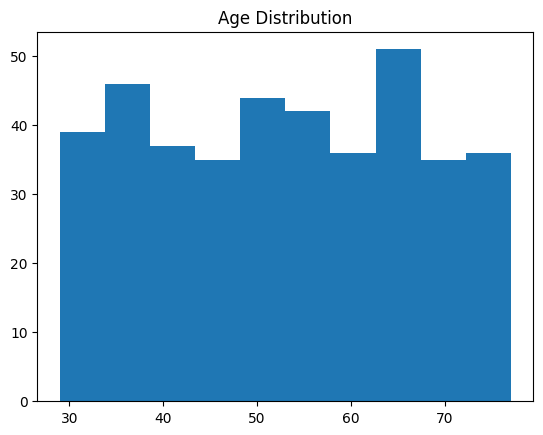

In [11]:
plt.hist(df["age"],bins=10)
plt.title("Age Distribution")
plt.show()

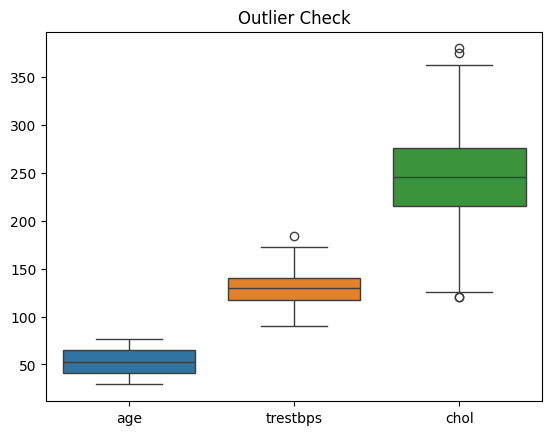

In [13]:
sns.boxplot(data = df[["age","trestbps","chol"]])
plt.title("Outlier Check")
plt.show()

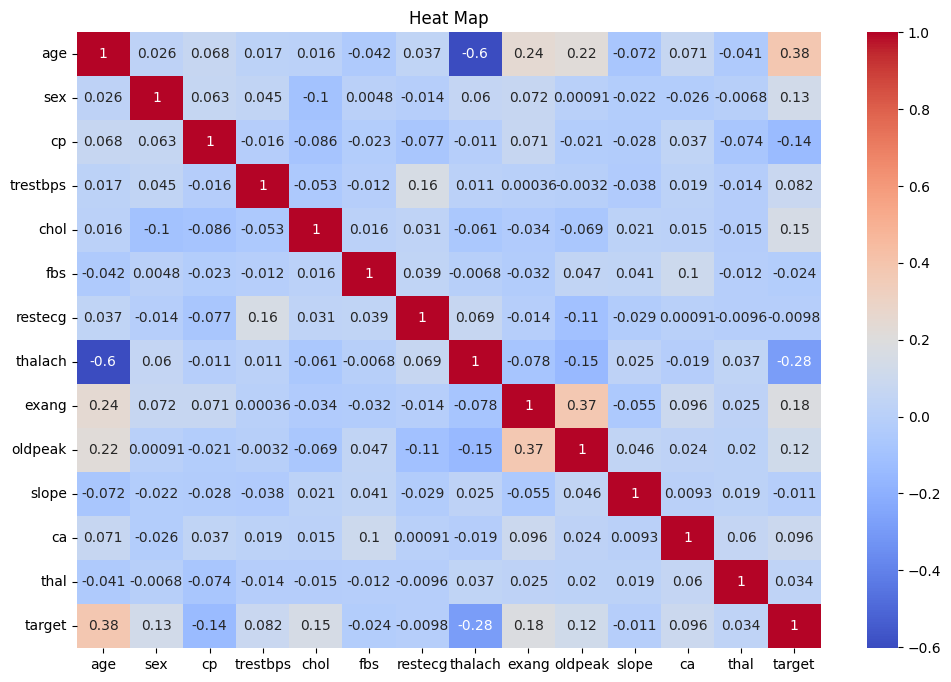

In [15]:
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr,annot = True,cmap="coolwarm")
plt.title("Heat Map")
plt.show()

In [16]:
x = df.drop("target",axis = 1)
y = df["target"]

x = pd.get_dummies(x,drop_first=True,dtype = int)

In [19]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size = 0.2,random_state = 42,stratify = y
)
scaler  = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [21]:
for k in [3,5,7,9]:
    knn = KNeighborsClassifier(n_neighbors = k)
    knn.fit(x_train_scaled,y_train)
    knn_pred = knn.predict(x_test_scaled)
    print("K=",k,"Accuracy=",accuracy_score(y_test,knn_pred))

K= 3 Accuracy= 0.5555555555555556
K= 5 Accuracy= 0.6296296296296297
K= 7 Accuracy= 0.6049382716049383
K= 9 Accuracy= 0.5802469135802469


In [22]:
for kernel in["linear","rbf","poly"]:
    svm = SVC(kernel=kernel)
    svm.fit(x_train_scaled,y_train)
    svm_pred = svm.predict(x_test_scaled)
    print("Kernel",kernel)
    print("Accuracy",accuracy_score(y_test,svm_pred))

Kernel linear
Accuracy 0.6666666666666666
Kernel rbf
Accuracy 0.6172839506172839
Kernel poly
Accuracy 0.6419753086419753


In [24]:
def evaluate(model, pred, x_train, x_test):
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
    print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, average="weighted", zero_division=0))
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print("Training Accuracy:", model.score(x_train, y_train))
    print("Testing Accuracy:", accuracy_score(y_test, pred))

print("KNN")
evaluate(knn, knn_pred, x_train_scaled,x_test_scaled)

print("\nSVM")
evaluate(svm, svm_pred, x_train_scaled, x_test_scaled)

KNN
Accuracy: 0.5802469135802469
Precision: 0.5801864696193542
Recall: 0.5802469135802469
F1 Score: 0.5798625243069687
Confusion Matrix:
 [[25 16]
 [18 22]]
Training Accuracy: 0.7375
Testing Accuracy: 0.5802469135802469

SVM
Accuracy: 0.6419753086419753
Precision: 0.641952697508253
Recall: 0.6419753086419753
F1 Score: 0.641866104831892
Confusion Matrix:
 [[27 14]
 [15 25]]
Training Accuracy: 0.859375
Testing Accuracy: 0.6419753086419753


In [27]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision_weighted",
    "Recall": "recall_weighted",
    "F1": "f1_weighted"
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="linear"))
])

knn_cv = cross_validate(knn, x_train, y_train, cv=cv, scoring=scoring)
svm_cv = cross_validate(svm, x_train, y_train, cv=cv, scoring=scoring)

results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [knn_cv["test_Accuracy"].mean(), svm_cv["test_Accuracy"].mean()],
    "Precision": [knn_cv["test_Precision"].mean(), svm_cv["test_Precision"].mean()],
    "Recall": [knn_cv["test_Recall"].mean(), svm_cv["test_Recall"].mean()],
    "F1 Score": [knn_cv["test_F1"].mean(), svm_cv["test_F1"].mean()]
})

print(results.round(3))
print("Best Model:", results.loc[results["Accuracy"].idxmax(), "Model"])

  Model  Accuracy  Precision  Recall  F1 Score
0   KNN     0.594      0.594   0.594     0.593
1   SVM     0.684      0.686   0.684     0.683
Best Model: SVM


In [30]:
svm = SVC(kernel="linear")
svm.fit(x_train_scaled, y_train)
svm_pred = svm.predict(x_test_scaled)

base_svm = SVC(kernel="linear")
ada = AdaBoostClassifier(
    estimator=base_svm,
    n_estimators=10,
    random_state=42
)

ada.fit(x_train_scaled, y_train)
ada_pred = ada.predict(x_test_scaled)

# Compare Accuracy
print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("AdaBoost SVM Accuracy:", accuracy_score(y_test, ada_pred))

SVM Accuracy: 0.6666666666666666
AdaBoost SVM Accuracy: 0.6296296296296297
